This notebook calculates the three theoretical visibility curves required for the lab:

1. **Single star**
2. **Binary, parallel baseline**
3. **Binary, 45° baseline**

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.special import j1

# Experimental parameters
source_distance_m = 21.81
wavelength_nm = 630.0

single_star_diameter_mm = 2.0
binary_component_diameter_mm = 1.0
binary_separation_mm = 2.0
binary_angles_deg = {"Parallel": 0.0, "45 degrees": 45.0}

baselines_mm = np.array([2.0, 4.0, 5.0, 6.0, 8.0, 10.0, 15.0])
baseline_grid_mm = np.linspace(0.0, 18.0, 1200)

wavelength_m = wavelength_nm * 1e-9
single_star_diameter_m = single_star_diameter_mm * 1e-3
binary_component_diameter_m = binary_component_diameter_mm * 1e-3
binary_separation_m = binary_separation_mm * 1e-3
baselines_m = baselines_mm * 1e-3
baseline_grid_m = baseline_grid_mm * 1e-3

print(f"Source distance: {source_distance_m:.2f} m")
print(f"Central wavelength: {wavelength_nm:.1f} nm")
print(f"Baselines: {baselines_mm} mm")

Source distance: 21.81 m
Central wavelength: 630.0 nm
Baselines: [ 2.  4.  5.  6.  8. 10. 15.] mm


For a uniform circular source of physical diameter $d$ at distance $L$, the angular diameter is

$$
\theta \simeq \frac{d}{L}.
$$

Its signed visibility is

$$
\mu(B)=\frac{2J_1(x)}{x},\qquad x=\frac{\pi B\theta}{\lambda}.
$$

For two equal uniform disks, the signed visibility is the single-component envelope multiplied by the binary modulation:

$$
\mu(B,\psi)=\frac{2J_1(x_*)}{x_*}
\cos\!\left(\frac{\pi B\theta_s\cos\psi}{\lambda}\right),
$$

where $\theta_*$ is the angular diameter of one component, $\theta_s$ is the angular separation, and $\psi$ is the angle between the baseline and the binary separation. The measured fringe contrast is $V=|\mu|$. A negative signed value indicates a $\pi$ phase shift (bright and dark fringes are exchanged).


In [26]:
def besinc(x):
    """Return 2*J1(x)/x, with the limiting value 1 at x=0."""
    x = np.asarray(x, dtype=float)
    y = np.ones_like(x)
    mask = np.abs(x) > 1e-12
    y[mask] = 2.0 * j1(x[mask]) / x[mask]
    return y


def disk_visibility(baseline_m, angular_diameter_rad):
    """Signed visibility of a uniform circular disk."""
    x = np.pi * np.asarray(baseline_m) * angular_diameter_rad / wavelength_m
    return besinc(x)


def binary_visibility(baseline_m, component_diameter_rad,
                       separation_rad, angle_deg):
    """Signed visibility of two equal uniform disks."""
    baseline_m = np.asarray(baseline_m, dtype=float)
    angle_rad = np.deg2rad(angle_deg)
    envelope = besinc(np.pi * baseline_m * component_diameter_rad / wavelength_m)
    phase = np.pi * baseline_m * separation_rad * np.cos(angle_rad) / wavelength_m
    return envelope * np.cos(phase)

theta_single = single_star_diameter_m / source_distance_m
theta_component = binary_component_diameter_m / source_distance_m
theta_separation = binary_separation_m / source_distance_m
rad_to_arcsec = 206265.0

print(f"Single-star angular diameter: {theta_single * rad_to_arcsec:.3f} arcsec")
print(f"Binary component angular diameter: {theta_component * rad_to_arcsec:.3f} arcsec")
print(f"Binary angular separation: {theta_separation * rad_to_arcsec:.3f} arcsec")

Single-star angular diameter: 18.915 arcsec
Binary component angular diameter: 9.457 arcsec
Binary angular separation: 18.915 arcsec


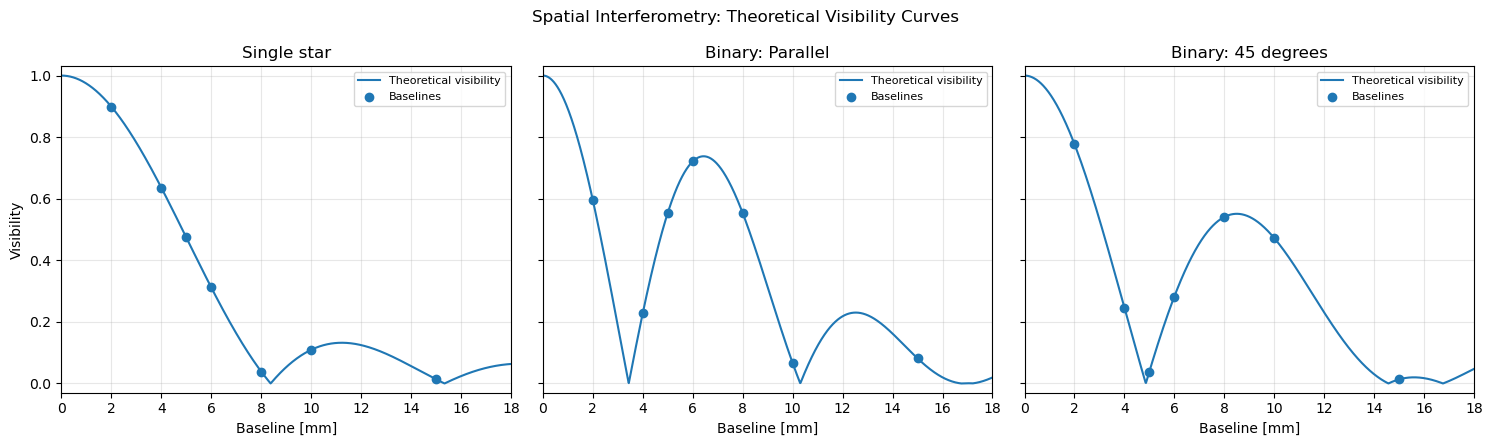

Saved: spatial_interferometry_visibility_curves.png


In [28]:
curves = {
    "Single star": np.abs(disk_visibility(baseline_grid_m, theta_single)),
}
points = {
    "Single star": np.abs(disk_visibility(baselines_m, theta_single)),
}

for label, angle in binary_angles_deg.items():
    curves[f"Binary: {label}"] = np.abs(
        binary_visibility(baseline_grid_m, theta_component, theta_separation, angle)
    )
    points[f"Binary: {label}"] = np.abs(
        binary_visibility(baselines_m, theta_component, theta_separation, angle)
    )

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (label, curve) in zip(axes, curves.items()):
    ax.plot(baseline_grid_mm, curve, label="Theoretical visibility")
    ax.scatter(baselines_mm, points[label], zorder=3,
               label="Baselines")
    ax.set(title=label, xlabel="Baseline [mm]", xlim=(0, baseline_grid_mm.max()), ylim=(-0.03, 1.03))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Visibility")
fig.suptitle("Spatial Interferometry: Theoretical Visibility Curves")
fig.tight_layout()
fig.savefig("spatial_interferometry_visibility_curves.png", dpi=200, bbox_inches="tight")
plt.show()

print("Saved: spatial_interferometry_visibility_curves.png")

In [30]:
results = pd.DataFrame({"Baseline [mm]": baselines_mm})
for label, value in points.items():
    results[f"{label} |μ|" ] = value

display(results.round(3))
results.to_csv("spatial_interferometry_visibility_values.csv", index=False,
               float_format="%.8f")

print("Saved: spatial_interferometry_visibility_values.csv")

,Baseline [mm],Single star |μ|,Binary: Parallel |μ|,Binary: 45 degrees |μ|
0,2.0,0.899,0.594,0.777
1,4.0,0.636,0.230,0.246
2,5.0,0.474,0.555,0.039
3,6.0,0.312,0.721,0.282
4,8.0,0.039,0.553,0.541
5,10.0,0.109,0.066,0.472
6,15.0,0.014,0.082,0.013


Saved: spatial_interferometry_visibility_values.csv


### Visibility Curves Fitting

The theoretical visibility curves are fitted to the measured data by adjusting the geometrical parameters.

For the single star, only the source distance $L$ is fitted. For the binary star, the source distance $L$ and the baseline orientation angle $\psi$ are fitted simultaneously, while all other parameters remain fixed at their nominal values.

The fitting is performed separately for each dataset. The resulting curves are compared with the original theoretical predictions to examine the influence of the geometrical parameters on the visibility.

,Configuration,L nominal [m],L fitted [m],L difference [m],Angle nominal [deg],Angle fitted [deg],Angle difference [deg],RMSE
0,Single star,21.81,31.1475,9.3375,NaN,NaN,NaN,0.0412
1,Binary: Parallel,21.81,23.4819,1.6719,0.0,0.0000,0.0000,0.0837
2,Binary: 45 degrees,21.81,25.3179,3.5079,45.0,46.2719,1.2719,0.0528


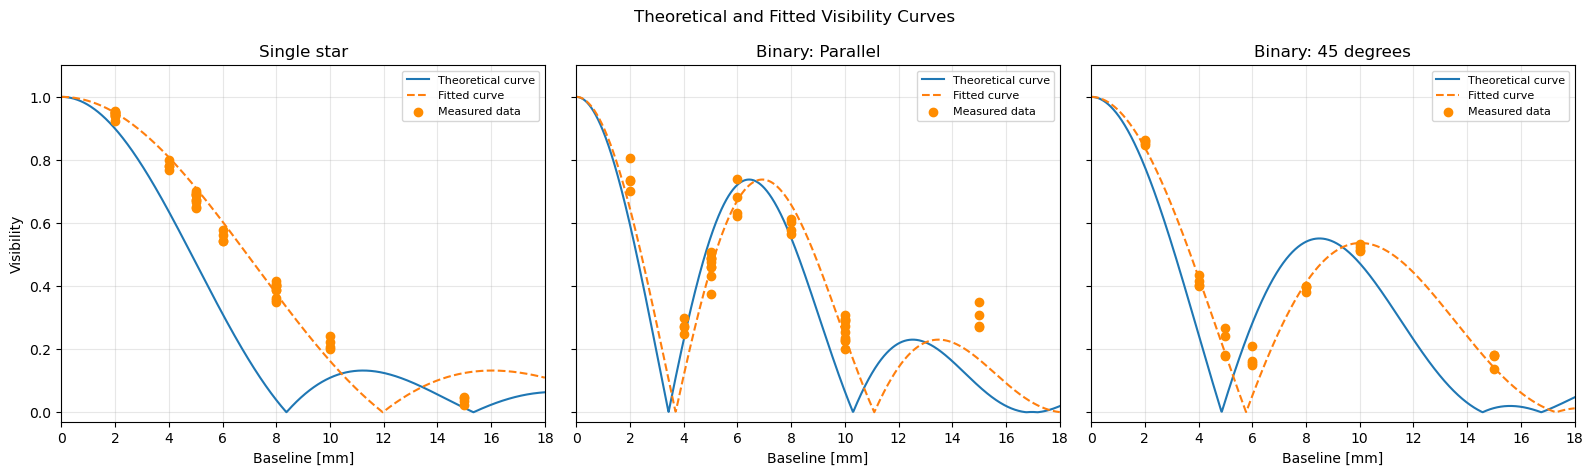

In [33]:
from scipy.optimize import least_squares

# ============================================================
# 1. Import measured data
# ============================================================

csv_path = "/Users/wang/Downloads/measured_visibility_coordinates.csv"

data = pd.read_csv(csv_path).rename(
    columns={"Visibility": "Measured visibility"}
)

data["Task"] = data["Task"].astype(str).str.strip().str.upper()

for col in ["Baseline [mm]", "Measured visibility"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(
    subset=["Task", "Baseline [mm]", "Measured visibility"]
)

data = data[
    data["Task"].isin(["A", "B", "C"]) &
    np.isfinite(data["Baseline [mm]"]) &
    np.isfinite(data["Measured visibility"])
].copy()


# ============================================================
# 2. Fitting configuration
# ============================================================

L_nominal = 21.81

L_bounds = (5.0, 50.0)
psi_bounds = (0.0, 90.0)

L_starts = [10.0, 15.0, 21.81, 30.0, 40.0]
psi_starts = [1.0, 15.0, 30.0, 45.0, 60.0, 75.0, 89.0]

task_labels = {
    "A": "Single star",
    "B": "Binary: Parallel",
    "C": "Binary: 45 degrees"
}

nominal_angles = {
    "A": None,
    "B": 0.0,
    "C": 45.0
}


# ============================================================
# 3. Theoretical visibility model
# ============================================================

def visibility_model(task, baseline_mm, L, psi=None):

    B = np.asarray(baseline_mm, dtype=float) * 1e-3

    if task == "A":
        theta = single_star_diameter_m / L
        x = np.pi * B * theta / wavelength_m
        return np.abs(besinc(x))

    theta_component = binary_component_diameter_m / L
    theta_separation = binary_separation_m / L

    x = np.pi * B * theta_component / wavelength_m

    phase = (
        np.pi * B * theta_separation
        * np.cos(np.deg2rad(psi)) / wavelength_m
    )

    return np.abs(besinc(x) * np.cos(phase))


# ============================================================
# 4. Fit the three datasets
# ============================================================

fit_results = {}
summary_rows = []

for task in ["A", "B", "C"]:

    group = data[data["Task"] == task]

    x_data = group["Baseline [mm]"].to_numpy()
    y_data = group["Measured visibility"].to_numpy()

    label = task_labels[task]

    # Define fitting parameters and initial guesses
    if task == "A":
        lower = [L_bounds[0]]
        upper = [L_bounds[1]]
        x_scale = [5.0]
        initial_guesses = [[L] for L in L_starts]

    else:
        lower = [L_bounds[0], psi_bounds[0]]
        upper = [L_bounds[1], psi_bounds[1]]
        x_scale = [5.0, 20.0]
        initial_guesses = [
            [L, psi]
            for L in L_starts
            for psi in psi_starts
        ]

    if len(group) < len(lower) + 1:
        raise ValueError(f"Insufficient data for {label}.")

    def residual_function(params):
        return visibility_model(task, x_data, *params) - y_data

    # Multi-start least-squares fitting
    candidates = []

    for p0 in initial_guesses:

        result = least_squares(
            residual_function,
            x0=p0,
            bounds=(lower, upper),
            loss="soft_l1",
            f_scale=0.05,
            x_scale=x_scale,
            max_nfev=20000
        )

        if result.success:
            candidates.append(result)

    if not candidates:
        raise RuntimeError(f"Fitting failed for {label}.")

    best = min(candidates, key=lambda r: r.cost)

    # Extract fitted parameters
    L_fit = best.x[0]
    psi_fit = best.x[1] if task != "A" else np.nan

    fitted = visibility_model(task, x_data, L_fit, psi_fit)

    fitted_curve = visibility_model(
        task, baseline_grid_mm, L_fit, psi_fit
    )

    rmse = np.sqrt(np.mean((y_data - fitted)**2))

    fit_results[task] = fitted_curve

    # Store fitting parameters
    summary_rows.append({
        "Configuration": label,
        "L nominal [m]": L_nominal,
        "L fitted [m]": L_fit,
        "L difference [m]": L_fit - L_nominal,
        "Angle nominal [deg]": nominal_angles[task],
        "Angle fitted [deg]": psi_fit,
        "Angle difference [deg]": (
            psi_fit - nominal_angles[task]
            if task != "A" else np.nan
        ),
        "RMSE": rmse
    })


# ============================================================
# 5. Display fitting parameters
# ============================================================

fit_summary = pd.DataFrame(summary_rows)

display(fit_summary.round(4))


# ============================================================
# 6. Plot theoretical and fitted curves
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8),
    sharey=True
)

for ax, task in zip(axes, ["A", "B", "C"]):

    label = task_labels[task]

    ax.plot(
        baseline_grid_mm,
        curves[label],
        label="Theoretical curve"
    )

    ax.plot(
        baseline_grid_mm,
        fit_results[task],
        "--",
        label="Fitted curve"
    )

    group = data[data["Task"] == task]

    ax.scatter(
        group["Baseline [mm]"],
        group["Measured visibility"],
        color="darkorange",
        zorder=3,
        label="Measured data"
    )

    ax.set(
        title=label,
        xlabel="Baseline [mm]",
        xlim=(0, 18),
        ylim=(-0.03, 1.1)
    )

    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Visibility")

fig.suptitle("Theoretical and Fitted Visibility Curves")
fig.tight_layout()
plt.show()

### Single-Parameter Fitting

The visibility curves are fitted to the measured data by adjusting one parameter at a time.

For the single star, only the source distance $L$ is fitted. For the binary configurations, the distance is fixed at $21.81\,\mathrm{m}$ and only the baseline orientation angle $\psi$ is fitted. All other parameters remain fixed at their nominal values.

The fitted curves are compared with the original theoretical curves and the measured data.

,Configuration,Fitted parameter,Nominal value,Fitted value,Difference,RMSE
0,Single star,Distance L [m],21.81,31.1474,9.3374,0.0412
1,Binary: Parallel,Baseline angle [deg],0.00,21.6143,21.6143,0.0983
2,Binary: 45 degrees,Baseline angle [deg],45.00,52.4293,7.4293,0.0727


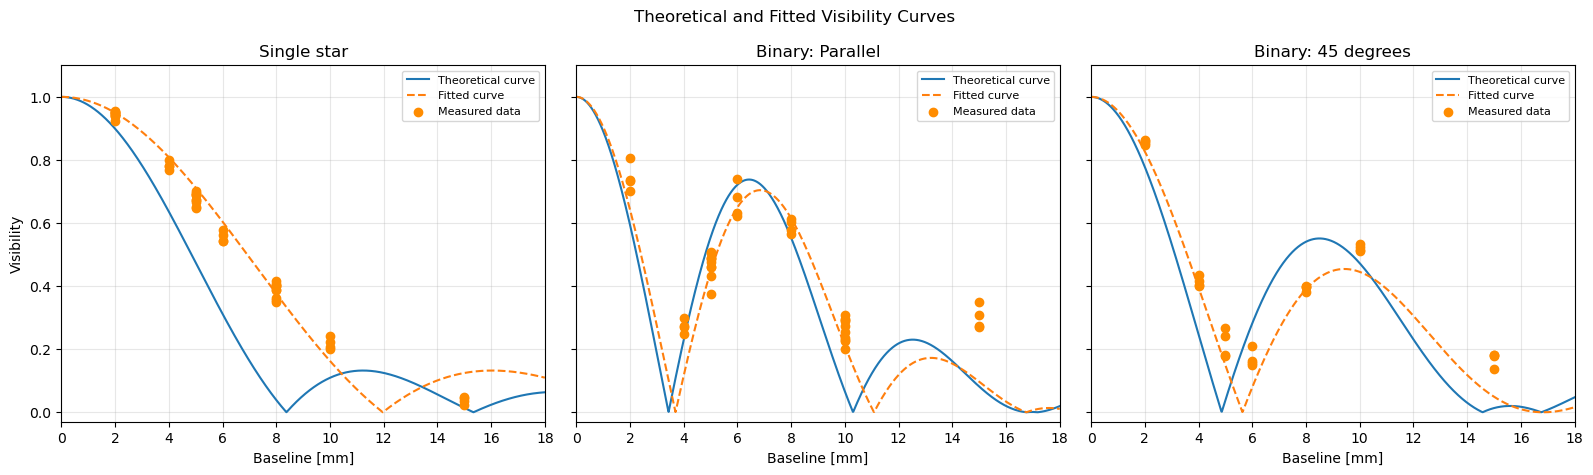

In [36]:
from scipy.optimize import least_squares

# ============================================================
# 1. Import measured data
# ============================================================

csv_path = "/Users/wang/Downloads/measured_visibility_coordinates.csv"

data = pd.read_csv(csv_path).rename(
    columns={"Visibility": "Measured visibility"}
)

data["Task"] = data["Task"].astype(str).str.strip().str.upper()

for col in ["Baseline [mm]", "Measured visibility"]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

data = data.dropna(
    subset=["Task", "Baseline [mm]", "Measured visibility"]
)

data = data[
    data["Task"].isin(["A", "B", "C"]) &
    np.isfinite(data["Baseline [mm]"]) &
    np.isfinite(data["Measured visibility"])
].copy()


# ============================================================
# 2. Fitting configuration
# ============================================================

L_nominal = source_distance_m

L_starts = np.linspace(5.1, 49.9, 30)
psi_starts = np.linspace(0.5, 89.5, 19)

task_labels = {
    "A": "Single star",
    "B": "Binary: Parallel",
    "C": "Binary: 45 degrees"
}

nominal_angles = {
    "A": None,
    "B": 0.0,
    "C": 45.0
}


# ============================================================
# 3. Fit the three datasets
# ============================================================

fit_curves = {}
summary_rows = []

for task in ["A", "B", "C"]:

    group = data[data["Task"] == task]

    B_data = group["Baseline [mm]"].to_numpy()
    V_data = group["Measured visibility"].to_numpy()

    label = task_labels[task]

    if len(group) < 2:
        raise ValueError(f"Insufficient data for {label}.")

    # Single star: fit source distance
    if task == "A":

        def residual_function(p):
            L = p[0]
            prediction = np.abs(
                disk_visibility(
                    B_data * 1e-3,
                    single_star_diameter_m / L
                )
            )
            return prediction - V_data

        lower, upper = [5.0], [50.0]
        starts = [[L] for L in L_starts]
        x_scale = [5.0]

    # Binary stars: fit baseline angle
    else:

        def residual_function(p):
            psi = p[0]
            prediction = np.abs(
                binary_visibility(
                    B_data * 1e-3,
                    binary_component_diameter_m / L_nominal,
                    binary_separation_m / L_nominal,
                    psi
                )
            )
            return prediction - V_data

        lower, upper = [0.0], [90.0]
        starts = [[psi] for psi in psi_starts]
        x_scale = [20.0]

    # Multi-start fitting
    candidates = []

    for p0 in starts:
        result = least_squares(
            residual_function,
            x0=p0,
            bounds=(lower, upper),
            loss="soft_l1",
            f_scale=0.05,
            x_scale=x_scale,
            max_nfev=20000
        )

        if result.success:
            candidates.append(result)

    if not candidates:
        raise RuntimeError(f"Fitting failed for {label}.")

    best = min(candidates, key=lambda r: r.cost)
    fitted_parameter = best.x[0]

    # Calculate fitted curve and RMSE
    if task == "A":

        fitted = np.abs(
            disk_visibility(
                B_data * 1e-3,
                single_star_diameter_m / fitted_parameter
            )
        )

        fitted_curve = np.abs(
            disk_visibility(
                baseline_grid_mm * 1e-3,
                single_star_diameter_m / fitted_parameter
            )
        )

        parameter_name = "Distance L [m]"
        nominal_value = L_nominal

    else:

        fitted = np.abs(
            binary_visibility(
                B_data * 1e-3,
                binary_component_diameter_m / L_nominal,
                binary_separation_m / L_nominal,
                fitted_parameter
            )
        )

        fitted_curve = np.abs(
            binary_visibility(
                baseline_grid_mm * 1e-3,
                binary_component_diameter_m / L_nominal,
                binary_separation_m / L_nominal,
                fitted_parameter
            )
        )

        parameter_name = "Baseline angle [deg]"
        nominal_value = nominal_angles[task]

    rmse = np.sqrt(np.mean((V_data - fitted)**2))

    fit_curves[task] = fitted_curve

    summary_rows.append({
        "Configuration": label,
        "Fitted parameter": parameter_name,
        "Nominal value": nominal_value,
        "Fitted value": fitted_parameter,
        "Difference": fitted_parameter - nominal_value,
        "RMSE": rmse
    })


# ============================================================
# 4. Display fitting parameters
# ============================================================

fit_summary = pd.DataFrame(summary_rows)

display(fit_summary.round(4))


# ============================================================
# 5. Plot theoretical and fitted curves
# ============================================================

fig, axes = plt.subplots(
    1, 3,
    figsize=(16, 4.8),
    sharey=True
)

for ax, task in zip(axes, ["A", "B", "C"]):

    label = task_labels[task]

    ax.plot(
        baseline_grid_mm,
        curves[label],
        label="Theoretical curve"
    )

    ax.plot(
        baseline_grid_mm,
        fit_curves[task],
        "--",
        label="Fitted curve"
    )

    group = data[data["Task"] == task]

    ax.scatter(
        group["Baseline [mm]"],
        group["Measured visibility"],
        color="darkorange",
        zorder=3,
        label="Measured data"
    )

    ax.set(
        title=label,
        xlabel="Baseline [mm]",
        xlim=(0, 18),
        ylim=(-0.03, 1.1)
    )

    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

axes[0].set_ylabel("Visibility")

fig.suptitle("Theoretical and Fitted Visibility Curves")
fig.tight_layout()
plt.show()